# E6. Đánh giá cuối và chọn bài nộp

Bước cuối của ML pipeline trước khi triển khai: đánh giá model đã chọn (Bài 05) và quyết định bài nộp. Cuộc thi chấm
trên tập test chia hai phần: public LB (20%, khoảng 60 nghìn dòng, thấy được trong lúc thi) và private LB (80%,
khoảng 240 nghìn dòng, công bố sau hạn). Mỗi đội chọn 2 bài, điểm cuối là điểm private cao hơn trong 2 bài.

> **Trong cuộc thi.** Nhóm nộp 36 bài từ 13 đến 31/10. Từ 19/10 nhóm giữ hai hướng: slot 1 theo CV (stacking trên
> pool công khai, trộn 20% một file công khai) và slot 2 theo đám đông trên public LB (các file trộn và dò public LB
> của cộng đồng). Bài chọn cuối: slot 1 `sub_slot1_v17b80_kirill20` (public 0,96190) và slot 2
> `sub_slot2_lineage_centroid` (public 0,96221). Kết quả private: **slot 1 đạt 0,96239, hạng 66 / khoảng 3.748 đội**;
> slot 2 đạt 0,96218.

Nội dung:
1. 36 bài nộp: public và private
2. Nhiễu của public LB: mô phỏng trên OOF
3. Đánh giá model cuối: ROC, AUC theo nhóm khách, lỗi theo mức tự tin
4. Tóm tắt, quyết định và bài học từ các kết quả âm

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve

from config import RESULTS_DIR, ROOT, TARGET
from data import load_data
import plot as P

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
COMP_OOF = Path(os.environ.get("COMP_OOF_DIR", ROOT.parent / "DoAn" / "oof"))
train, _ = load_data()
y, fold = train[TARGET].values, train["fold"].values

## 1. 36 bài nộp: public và private

Mỗi bài được xếp vào một nhóm theo cách tạo:
- model đơn hoặc stacking chỉ gồm model của nhóm (không dùng OOF công khai);
- stacking trên pool OOF công khai, chọn theo CV;
- stacking trộn nhẹ (5–30% theo thứ hạng) với một file công khai hoặc với stacking của nhóm;
- file trộn mạnh hoặc dò public LB (50% trở lên là file công khai, hoặc chép nguyên file).

In [2]:
GROUP = {
    "sub_stack_lgb_v1.csv": "model của nhóm", "sub_lgb_fe4_teachers.csv": "model của nhóm",
    "sub_A_lgb_v1.csv": "model của nhóm", "submission_quan_power_v3.csv": "model của nhóm",
    "sub_cs116_llr_xgb_v1.csv": "model của nhóm", "sub_team_stack_v2.csv": "model của nhóm",
    "sub_stack_lr_clean_public.csv": "stacking theo CV", "sub_stack_fw_p247.csv": "stacking theo CV",
    "sub_stack_v10_drop_forge.csv": "stacking theo CV", "sub_stack_v17_qft15.csv": "stacking theo CV",
    "submission_metaLR_182_only_v7.csv": "stacking theo CV",
    "sub_track3_fw_p247_x_96183_w03.csv": "stacking trộn nhẹ", "sub_track3_v10_drop_forge_x_96183_w03.csv": "stacking trộn nhẹ",
    "sub_track3_v10_drop_both_x_96183_w03.csv": "stacking trộn nhẹ", "sub_final_p247_team_blend_w05.csv": "stacking trộn nhẹ",
    "sub_final_p247_team_blend_w15.csv": "stacking trộn nhẹ", "sub_case3_both_models_blend_w10.csv": "stacking trộn nhẹ",
    "sub_case3_both_models_blend_w15.csv": "stacking trộn nhẹ", "sub_hedge_fw_noforge_x_hanif96198_w03.csv": "stacking trộn nhẹ",
    "sub_slot1_stack80_kirill20.csv": "stacking trộn nhẹ", "sub_slot1_v14rm80_kirill20.csv": "stacking trộn nhẹ",
    "sub_slot1_v17qft80_kirill20.csv": "stacking trộn nhẹ", "sub_slot1_v17b80_kirill20.csv": "stacking trộn nhẹ",
    "submission.csv": "trộn mạnh / dò public LB", "sub_hedge_fw_noforge_x_gp96197_w05.csv": "trộn mạnh / dò public LB",
    "sub_hedge_fw_noforge_x_hanif96198_w05.csv": "trộn mạnh / dò public LB",
    "sub_slot2_hblend_teacher.csv": "trộn mạnh / dò public LB", "sub_slot2_mix50_nina210.csv": "trộn mạnh / dò public LB",
    "sub_slot2_mix50_tabpfn.csv": "trộn mạnh / dò public LB", "sub_slot2_step20_v17b.csv": "trộn mạnh / dò public LB",
    "sub_slot2_step10_v17b.csv": "trộn mạnh / dò public LB", "sub_slot2_anti10_v17b.csv": "trộn mạnh / dò public LB",
    "sub_slot2_lineage_centroid.csv": "trộn mạnh / dò public LB",
    "submission_candidate_first_v7.csv": "trộn mạnh / dò public LB",
    "sub_optimal7_anchor96195_blend_w05.csv": "trộn mạnh / dò public LB",
    "sub_super_team_p247_blend_w10.csv": "stacking trộn nhẹ",
}
subs = pd.read_csv(RESULTS_DIR / "competition_submissions.csv")
subs["nhóm"] = subs["file"].map(GROUP)
assert subs["nhóm"].notna().all(), subs.loc[subs["nhóm"].isna(), "file"].tolist()
subs["ngày"] = pd.to_datetime(subs["date"]).dt.strftime("%d/%m")
subs["hạng public (trong 36)"] = subs["public"].rank(ascending=False, method="min").astype(int)
subs["hạng private (trong 36)"] = subs["private"].rank(ascending=False, method="min").astype(int)
known = subs
summary = known.groupby("nhóm").agg(số_bài=("file", "size"), public_TB=("public", "mean"), public_max=("public", "max"),
                                    private_TB=("private", "mean"), private_max=("private", "max")).round(5)
summary.to_csv(RESULTS_DIR / "E6_submission_groups.csv")
print(f"Tương quan Spearman public–private trên 36 bài: {spearmanr(known['public'], known['private']).statistic:.3f}")
top = known[known["nhóm"] != "model của nhóm"]
print(f"Bỏ nhóm model đơn ({len(top)} bài stacking / trộn): {spearmanr(top['public'], top['private']).statistic:.3f}")
summary

Tương quan Spearman public–private trên 36 bài: 0.108
Bỏ nhóm model đơn (30 bài stacking / trộn): -0.553


,số_bài,public_TB,public_max,private_TB,private_max
nhóm,,,,,
model của nhóm,6,0.96018,0.96068,0.96104,0.96157
stacking theo CV,5,0.96183,0.96184,0.96237,0.96239
stacking trộn nhẹ,13,0.96185,0.96191,0.96238,0.96239
trộn mạnh / dò public LB,12,0.96205,0.96221,0.96228,0.96237


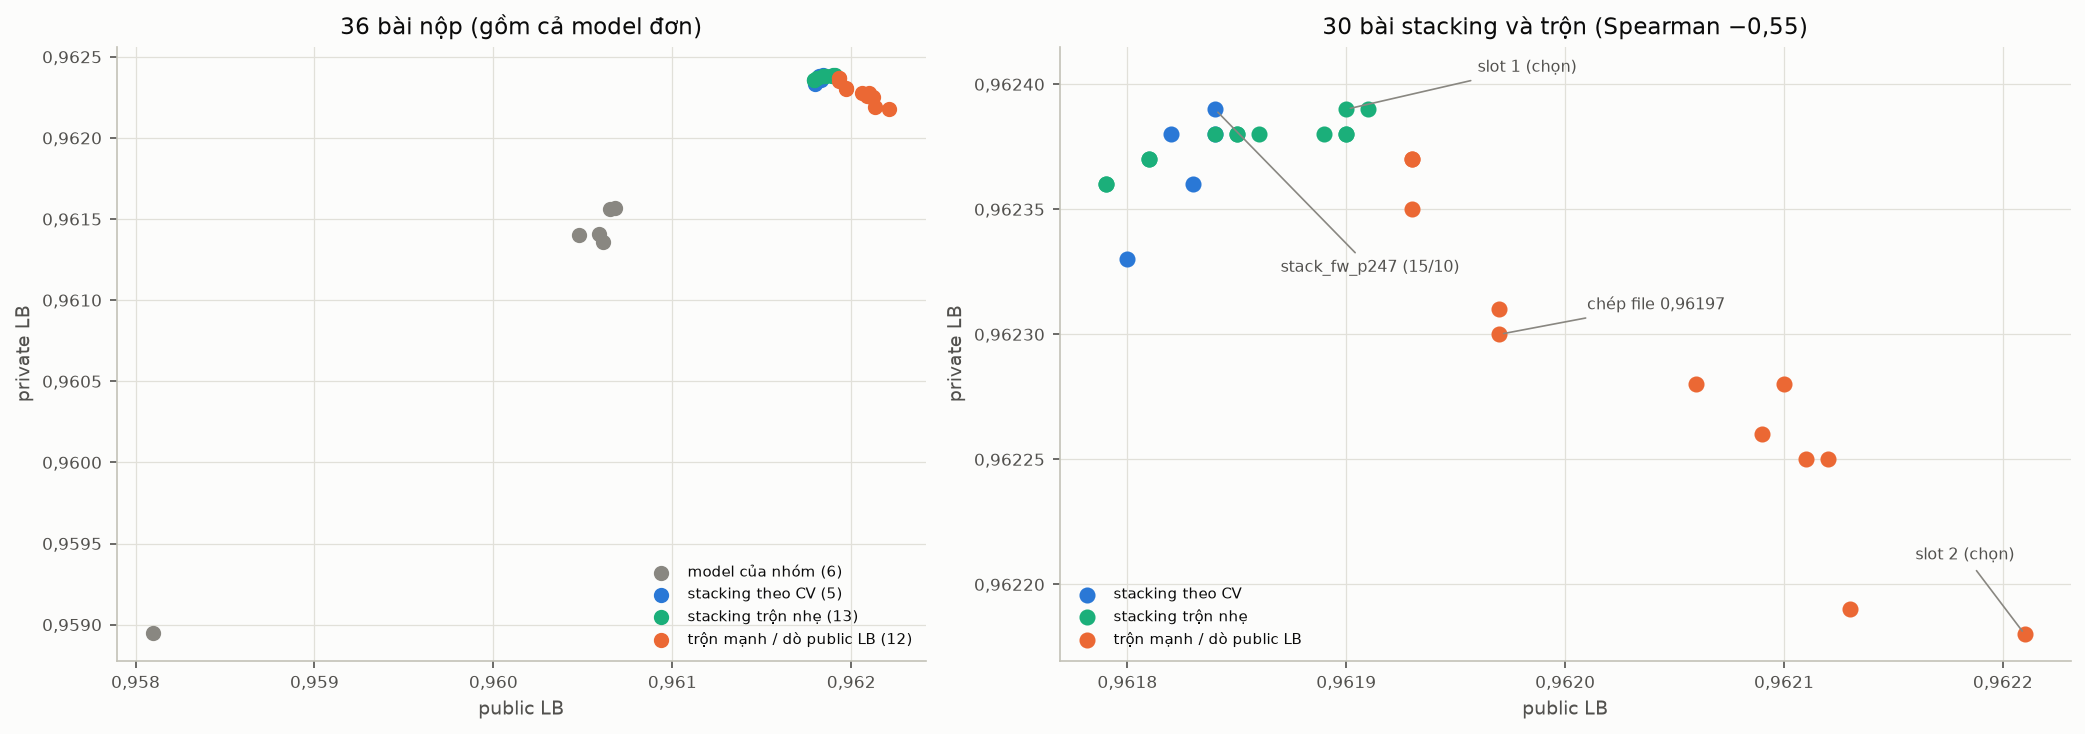

In [3]:
COL = {"model của nhóm": P.INK_3, "stacking theo CV": P.BLUE, "stacking trộn nhẹ": P.AQUA,
       "trộn mạnh / dò public LB": P.ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for g, d in known.groupby("nhóm"):
    ax.scatter(d["public"], d["private"], s=40, color=COL[g], label=f"{g} ({len(d)})", zorder=3)
ax.set_xlabel("public LB")
ax.set_ylabel("private LB")
ax.set_title("36 bài nộp (gồm cả model đơn)")
ax.legend(loc="lower right", fontsize=7)
ax = axes[1]
for g, d in top.groupby("nhóm"):
    ax.scatter(d["public"], d["private"], s=45, color=COL[g], label=g, zorder=3)
for f, lab, xy in [("sub_slot1_v17b80_kirill20.csv", "slot 1 (chọn)", (0.96196, 0.962405)),
                   ("sub_slot2_lineage_centroid.csv", "slot 2 (chọn)", (0.96216, 0.96221)),
                   ("submission.csv", "chép file 0,96197", (0.96201, 0.96231)),
                   ("sub_stack_fw_p247.csv", "stack_fw_p247 (15/10)", (0.96187, 0.962325))]:
    r = subs[subs["file"] == f].iloc[0]
    ax.annotate(lab, (r["public"], r["private"]), xytext=xy, fontsize=7.5, color=P.INK_2,
                arrowprops=dict(arrowstyle="-", color=P.INK_3, lw=0.8))
ax.set_xlabel("public LB")
ax.set_ylabel("private LB")
ax.set_title("30 bài stacking và trộn (Spearman " + f"{spearmanr(top['public'], top['private']).statistic:+.2f}".replace(".", ",") + ")")
ax.set_ylim(top=0.962415)
ax.legend(loc="lower left", fontsize=7)
fig.tight_layout()
P.save(fig, "E6_01_public_private")

In [4]:
subs.sort_values("private", ascending=False)[["ngày", "file", "nhóm", "public", "private", "hạng public (trong 36)",
                                               "hạng private (trong 36)"]].reset_index(drop=True)

,ngày,file,nhóm,public,private,hạng public (trong 36),hạng private (trong 36)
0,20/10,sub_slot1_stack80_kirill20.csv,stacking trộn nhẹ,0.96191,0.96239,13,1
1,15/10,sub_stack_fw_p247.csv,stacking theo CV,0.96184,0.96239,21,1
2,27/10,sub_slot1_v17b80_kirill20.csv,stacking trộn nhẹ,0.96190,0.96239,14,1
3,19/10,sub_track3_v10_drop_both_x_96183_w03.csv,stacking trộn nhẹ,0.96185,0.96238,19,4
4,25/10,sub_stack_v17_qft15.csv,stacking theo CV,0.96184,0.96238,21,4
5,20/10,sub_slot1_v14rm80_kirill20.csv,stacking trộn nhẹ,0.96189,0.96238,17,4
6,17/10,sub_track3_fw_p247_x_96183_w03.csv,stacking trộn nhẹ,0.96186,0.96238,18,4
7,19/10,sub_hedge_fw_noforge_x_hanif96198_w03.csv,stacking trộn nhẹ,0.96190,0.96238,14,4
8,18/10,sub_final_p247_team_blend_w05.csv,stacking trộn nhẹ,0.96184,0.96238,21,4
9,25/10,sub_slot1_v17qft80_kirill20.csv,stacking trộn nhẹ,0.96190,0.96238,14,4


**Nhận xét mục 1**
- Nhóm bài trộn mạnh hoặc dò public LB có public trung bình cao nhất (0,96205, cao nhất 0,96221), nhưng private
  trung bình thấp nhất trong các nhóm dùng stacking (0,96228). Hai nhóm stacking theo CV và stacking trộn nhẹ có public
  thấp hơn (0,96183 và 0,96185) nhưng private cao hơn (0,96237 và 0,96238).
- Trên 30 bài stacking và trộn, tương quan Spearman giữa public và private là −0,55. Nếu chọn bài theo public LB thì
  sẽ chọn sai: bài có public cao nhất (slot 2, 0,96221) lại có private thấp nhất (0,96218).
- Slot 1 đạt private cao nhất (0,96239), bằng `stack_fw_p247` nộp từ 15/10. Các cải tiến stacking sau đó (bỏ member
  Forge, FWLS, thêm Q-FT) đều nằm trong khoảng 0,96236–0,96239 trên private, tức là không thay đổi được kết quả
  cuối, đúng với dự đoán từ CV (mỗi cải tiến chỉ vài phần triệu).
- Model đơn của nhóm có private cao hơn public khoảng 9×10⁻⁴, và 35/36 bài có private cao hơn public (trừ slot 2).
  Phần private của tập test có vẻ dễ hơn phần public, nên chỉ so sánh các bài với nhau trên cùng một phần.

## 2. Nhiễu của public LB: mô phỏng trên OOF
Không có nhãn của tập test, nên nhóm mô phỏng bằng OOF trên tập train. Lấy hai bộ dự đoán OOF, chọn ngẫu nhiên 60
nghìn dòng (cỡ public LB) hoặc 240 nghìn dòng (cỡ private LB), tính chênh lệch AUC giữa hai bộ; lặp 1.000 lần. Độ
lệch chuẩn của chênh lệch cho biết public LB phân biệt được hai bài khác nhau bao nhiêu.

Ba cặp được chọn để có tương quan khác nhau: hai bản stacking gần như giống nhau, stacking công khai so với stacking
chỉ của nhóm, và stacking so với LightGBM đơn.

In [5]:
NOISE = RESULTS_DIR / "E6_lb_noise.csv"
PAIRS = [("stack_v17b_qft15", "stack_fw_p247", "hai bản stacking pool công khai"),
         ("stack_v17b_qft15", "stack_team_tfm", "stacking công khai / stacking nhóm + foundation model"),
         ("stack_v17b_qft15", "A_lgb_v2", "stacking công khai / LightGBM đơn")]
if not NOISE.exists() and (COMP_OOF / "oof_stack_v17b_qft15.npy").exists():
    rng = np.random.default_rng(0)
    rows = []
    for a, b, desc in PAIRS:
        pa, pb = np.load(COMP_OOF / f"oof_{a}.npy"), np.load(COMP_OOF / f"oof_{b}.npy")
        full = roc_auc_score(y, pa) - roc_auc_score(y, pb)
        rho = spearmanr(pa, pb).statistic
        for n in (60_000, 240_000):
            d = []
            for _ in range(1000):
                idx = rng.choice(len(y), n, replace=False)
                d.append(roc_auc_score(y[idx], pa[idx]) - roc_auc_score(y[idx], pb[idx]))
            d = np.array(d)
            rows.append({"cặp": desc, "A": a, "B": b, "tương quan rank": round(rho, 5), "số dòng": n,
                         "chênh trên toàn bộ OOF": full, "sd chênh": d.std(),
                         "tỉ lệ đảo dấu": float(np.mean(np.sign(d) != np.sign(full)))})
        print(desc, "xong")
    pd.DataFrame(rows).to_csv(NOISE, index=False)
noise = pd.read_csv(NOISE)
noise.style.format({"chênh trên toàn bộ OOF": "{:.2e}", "sd chênh": "{:.2e}", "tỉ lệ đảo dấu": "{:.1%}"})

,cặp,A,B,tương quan rank,số dòng,chênh trên toàn bộ OOF,sd chênh,tỉ lệ đảo dấu
0,hai bản stacking pool công khai,stack_v17b_qft15,stack_fw_p247,0.999680,60000,5.72e-06,2.32e-05,39.4%
1,hai bản stacking pool công khai,stack_v17b_qft15,stack_fw_p247,0.999680,240000,5.72e-06,9.40e-06,27.8%
2,stacking công khai / stacking nhóm + foundation model,stack_v17b_qft15,stack_team_tfm,0.992130,60000,4.21e-04,1.12e-04,0.0%
3,stacking công khai / stacking nhóm + foundation model,stack_v17b_qft15,stack_team_tfm,0.992130,240000,4.21e-04,4.80e-05,0.0%
4,stacking công khai / LightGBM đơn,stack_v17b_qft15,A_lgb_v2,0.976010,60000,1.33e-03,1.95e-04,0.0%
5,stacking công khai / LightGBM đơn,stack_v17b_qft15,A_lgb_v2,0.976010,240000,1.33e-03,7.98e-05,0.0%


**Nhận xét mục 2**
- Với hai bản stacking gần như giống nhau (tương quan 0,9997, chênh thật 6×10⁻⁶), độ lệch chuẩn của chênh lệch là
  2,3×10⁻⁵ trên 60 nghìn dòng và 9×10⁻⁶ trên 240 nghìn dòng. Thứ tự giữa hai bài bị đảo ở 39% số lần trên cỡ public
  và 28% trên cỡ private. Các bài stacking của nhóm chỉ chênh nhau trên public trong khoảng 0,96182–0,96191, nằm
  trong mức nhiễu này.
- Với hai model khác nhau rõ (chênh thật 4,2×10⁻⁴ và 1,3×10⁻³), thứ tự không bao giờ bị đảo. Public LB chỉ phân
  biệt được những khác biệt lớn hơn khoảng 5×10⁻⁵.
- Độ lệch chuẩn giảm khoảng 2,5 lần khi số dòng tăng 4 lần, gần với quy luật 1/√n. Đây là cùng hiện tượng như khi so
  một lần holdout với K-fold ở E0: tập đánh giá càng nhỏ thì kết quả càng dao động.

## 3. Đánh giá model cuối
Slot 1 là 0,8 × thứ hạng của stacking `stack_v17b_qft15` cộng 0,2 × thứ hạng một file công khai không có OOF, nên
phần đánh giá dùng OOF của `stack_v17b_qft15` (CV 0,962224). So sánh với LightGBM đơn của nhóm (`A_lgb_v2`) và
stacking chỉ gồm 25 OOF sạch của nhóm (E3, E5) để thấy phần tăng nằm ở đâu.

In [6]:
EVAL = RESULTS_DIR / "E6_segments.csv"
MODELS = {"LightGBM đơn (A_lgb_v2)": "A_lgb_v2", "stacking pool công khai (slot 1)": "stack_v17b_qft15"}
if (COMP_OOF / "oof_stack_v17b_qft15.npy").exists():
    preds = {k: np.load(COMP_OOF / f"oof_{v}.npy") for k, v in MODELS.items()}
else:
    preds = None

if preds is not None and not EVAL.exists():
    seg = {"Type of Travel": train["Type of Travel"], "Class": train["Class"], "Customer Type": train["Customer Type"],
           "Age": pd.cut(train["Age"], [0, 25, 40, 60, 100], labels=["a ≤25", "b 26–40", "c 41–60", "d >60"]).astype(str),
           "có trễ chuyến": np.where(train["Departure Delay in Minutes"] > 0, "có", "không")}
    rows = []
    for col, s in seg.items():
        for v in sorted(pd.Series(s).unique()):
            m = (pd.Series(s) == v).values
            row = {"cột": col, "giá trị": v, "số dòng": int(m.sum()), "tỉ lệ hài lòng": y[m].mean()}
            for k, p in preds.items():
                row[f"AUC {k}"] = roc_auc_score(y[m], p[m])
            rows.append(row)
    pd.DataFrame(rows).to_csv(EVAL, index=False)
segs = pd.read_csv(EVAL)
k1, k2 = [f"AUC {k}" for k in MODELS]
segs["Δ stacking − LightGBM"] = segs[k2] - segs[k1]
segs.round(5)

,cột,giá trị,số dòng,tỉ lệ hài lòng,AUC LightGBM đơn (A_lgb_v2),AUC stacking pool công khai (slot 1),Δ stacking − LightGBM
0,Type of Travel,Business travel,497441,0.58434,0.95764,0.95932,0.00168
1,Type of Travel,Personal Travel,202194,0.09726,0.83283,0.83595,0.00312
2,Class,Business,342212,0.72531,0.94040,0.94287,0.00246
3,Class,Eco,327404,0.16756,0.90494,0.90734,0.00240
4,Class,Eco Plus,30019,0.24218,0.93198,0.93441,0.00243
5,Customer Type,Loyal Customer,576990,0.49515,0.96133,0.96265,0.00132
6,Customer Type,disloyal Customer,122645,0.20095,0.92450,0.92718,0.00268
7,Age,a ≤25,141374,0.24933,0.93929,0.94124,0.00195
8,Age,b 26–40,225837,0.39111,0.95763,0.95912,0.00150
9,Age,c 41–60,301674,0.60462,0.95729,0.95877,0.00148


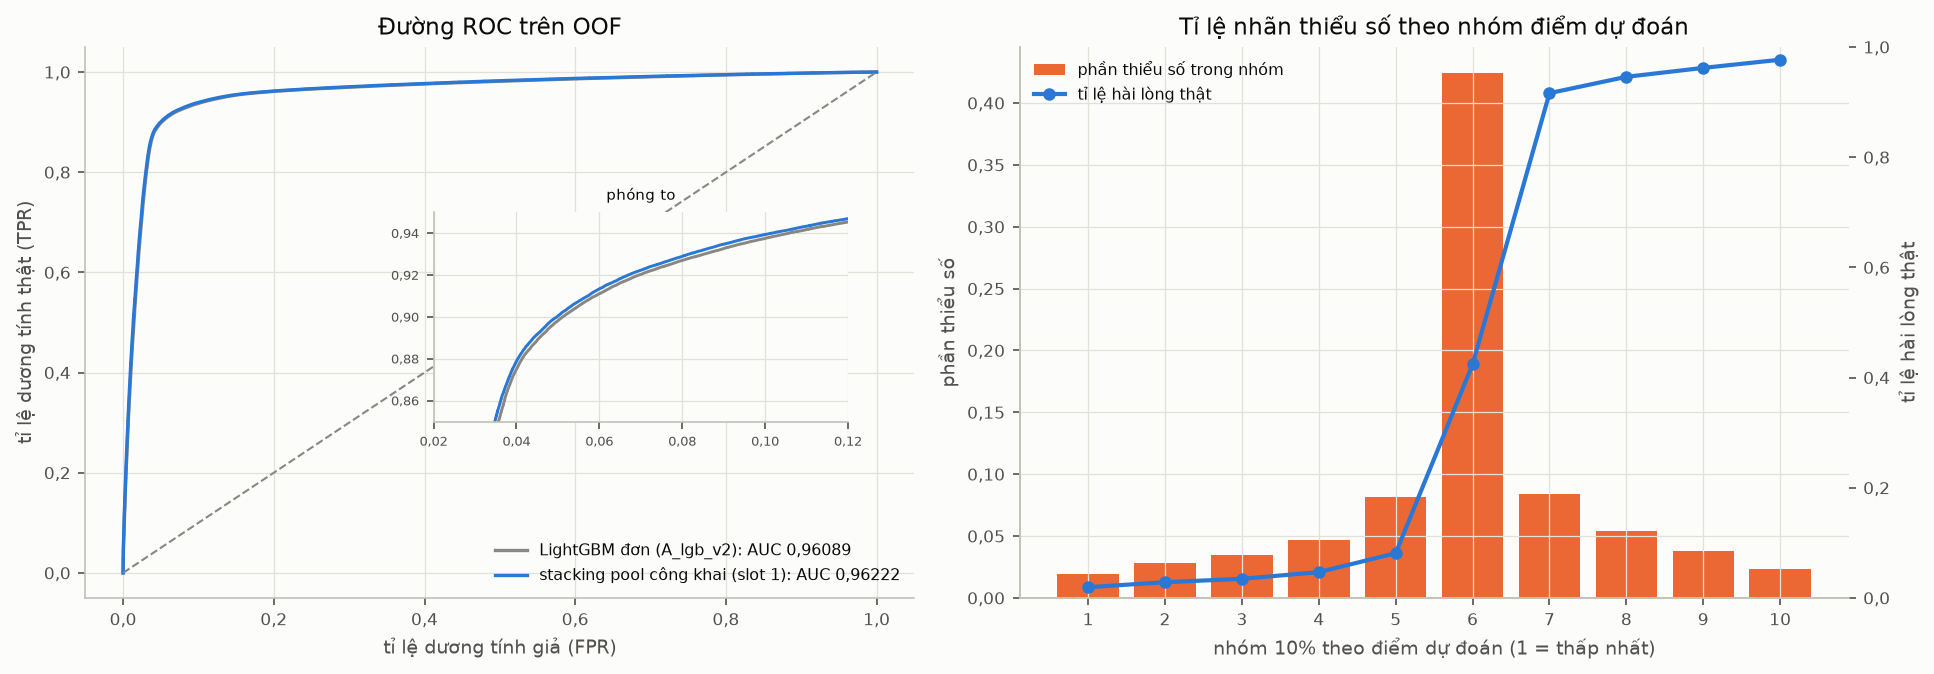

 nhóm 10%  tỉ lệ hài lòng  phần thiểu số
        1          0.0194         0.0194
        2          0.0285         0.0285
        3          0.0347         0.0347
        4          0.0468         0.0468
        5          0.0812         0.0812
        6          0.4241         0.4241
        7          0.9162         0.0838
        8          0.9459         0.0541
        9          0.9621         0.0379
       10          0.9769         0.0231


In [7]:
if preds is not None:
    p = preds["stacking pool công khai (slot 1)"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    ax = axes[0]
    for (k, pr), c in zip(preds.items(), [P.INK_3, P.BLUE]):
        fpr, tpr, _ = roc_curve(y, pr)
        ax.plot(fpr, tpr, color=c, lw=1.6, label=f"{k}: AUC {roc_auc_score(y, pr):.5f}")
    ax.plot([0, 1], [0, 1], color=P.REF, lw=1, ls="--")
    ax.set_xlabel("tỉ lệ dương tính giả (FPR)")
    ax.set_ylabel("tỉ lệ dương tính thật (TPR)")
    ax.set_title("Đường ROC trên OOF")
    ax.legend(loc="lower right", fontsize=7.5)
    ins = ax.inset_axes([0.42, 0.32, 0.5, 0.38])
    for (k, pr), c in zip(preds.items(), [P.INK_3, P.BLUE]):
        fpr, tpr, _ = roc_curve(y, pr)
        ins.plot(fpr, tpr, color=c, lw=1.4)
    ins.set_xlim(0.02, 0.12)
    ins.set_ylim(0.85, 0.95)
    ins.tick_params(labelsize=6)
    ins.set_title("phóng to", fontsize=7)
    ax = axes[1]
    # OOF của stacking là điểm đã co lại sau bước trộn, chưa hiệu chỉnh thành xác suất, nên không dùng ngưỡng 0,5.
    # Chia 10 nhóm theo thứ hạng điểm; trong mỗi nhóm, "phần thiểu số" là tỉ lệ dòng mang nhãn ngược với đa số.
    dec = np.minimum((rankdata(p) - 1) * 10 // len(p), 9).astype(int)
    rate = np.array([y[dec == d].mean() for d in range(10)])
    minority = np.minimum(rate, 1 - rate)
    pd.DataFrame({"nhóm 10%": range(1, 11), "tỉ lệ hài lòng": rate, "phần thiểu số": minority}).to_csv(
        RESULTS_DIR / "E6_deciles.csv", index=False)
    ax.bar(range(1, 11), minority, color=P.ORANGE, label="phần thiểu số trong nhóm")
    ax2 = ax.twinx()
    ax2.plot(range(1, 11), rate, color=P.BLUE, marker="o", label="tỉ lệ hài lòng thật")
    ax2.set_ylim(0, 1)
    ax2.grid(False)
    ax.set_xlabel("nhóm 10% theo điểm dự đoán (1 = thấp nhất)")
    ax.set_ylabel("phần thiểu số")
    ax2.set_ylabel("tỉ lệ hài lòng thật")
    ax.set_xticks(range(1, 11))
    ax.set_title("Tỉ lệ nhãn thiểu số theo nhóm điểm dự đoán")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=7.5)
    fig.tight_layout()
    P.save(fig, "E6_02_roc_errors")
    print(pd.read_csv(RESULTS_DIR / "E6_deciles.csv").round(4).to_string(index=False))

**Nhận xét mục 3**
- Trên OOF, stacking đạt AUC 0,96222 so với 0,96089 của LightGBM đơn. Đường ROC của hai model gần như trùng nhau;
  phần chênh chỉ thấy rõ khi phóng to vùng false positive rate 2–12%.
- Stacking tốt hơn LightGBM ở mọi nhóm khách, từ 1,3×10⁻³ đến 3,1×10⁻³. Mức tăng lớn nhất ở khách đi việc riêng
  (+3,1×10⁻³) và khách không thân thiết (+2,7×10⁻³).
- Khách đi việc riêng (Personal Travel) là nhóm khó nhất: AUC chỉ 0,836, so với 0,959 ở khách công tác. Nhóm này
  chiếm 29% số dòng nhưng chỉ 9,7% hài lòng. Khách trên 60 tuổi (0,903) và hạng Eco (0,907) cũng khó hơn mức chung.
- Chia 10 nhóm theo điểm dự đoán: ở 9 nhóm, tỉ lệ nhãn thiểu số chỉ 2–8%; riêng nhóm thứ 6 có 42%. Như vậy phần lớn
  các dòng khó phân biệt nằm trong khoảng 10% dữ liệu ở giữa thang điểm. Ở E5, phân tích lỗi tự tin cho thấy lỗi ở
  các nhóm hai đầu không đoán được từ feature, nhiều khả năng là nhiễu nhãn.

## 4. Tóm tắt và quyết định

| | Kết quả |
| --- | --- |
| Bài chọn cuối | slot 1 (CV): private 0,96239, hạng 66 / khoảng 3.748; slot 2 (đám đông public LB): private 0,96218 |
| Public so với private (30 bài stacking và trộn) | Spearman −0,55; bài public cao nhất có private thấp nhất |
| Nhiễu public LB với hai bài gần giống nhau | độ lệch chuẩn 2,3×10⁻⁵, đảo thứ tự 39% số lần |
| Model cuối trên OOF | AUC 0,96222; hơn LightGBM đơn ở mọi nhóm khách; khó nhất là khách đi việc riêng (0,836) |

**Quyết định:**
1. Bài chọn theo CV đạt private cao nhất (0,96239). Private trung bình của nhóm bài stacking theo CV cao hơn nhóm bài
   dò public LB 9×10⁻⁵. Với cuộc thi sau, nhóm sẽ chọn ít nhất một bài theo CV.
2. Hai slot theo hai hướng khác nhau không làm giảm điểm cuối, vì điểm cuối là điểm private cao hơn của hai bài. Lần
   này slot 2 không giúp; slot này chỉ có ích nếu các file trộn của cộng đồng thật sự tốt hơn stacking trên private.
3. Từ khoảng 19/10, các thay đổi stacking chỉ còn vài ×10⁻⁶, nhỏ hơn nhiễu của cả public lẫn private. Sau mốc đó,
   tìm model khác loại (như Q-FT) có cơ sở hơn dò thêm stacker hay trộn file.

**Đã thử nhưng không giữ**

| Ý tưởng | Thời điểm | Public | Private | Lý do không giữ |
| --- | --- | --- | --- | --- |
| Track 3: 0,7 stacking + 0,3 file công khai 0,96183 (3 bản) | 17/10, 19/10 | 0,96185–0,96186 | 0,96238 | không có cơ sở CV (v7: +0,3×10⁻⁶ đến +8,7×10⁻⁶); public tăng trong mức nhiễu |
| Ngoại suy theo hướng tăng public (T > 1) | 18/10 | – | – | trên OOF giảm 1,2×10⁻⁵ đến 2,8×10⁻⁴, 0/5 fold; không nộp |
| Trộn 50/50 stacking với file công khai 0,96197 / 0,96198 | 19/10 | 0,96193 | 0,96237 | dò public, không có CV |
| Nộp nguyên file meta-stack công khai 0,96197 | 19/10 | 0,96197 | 0,96230 | như trên |
| Slot 2 trộn theo cổng bất đồng, teacher 35% (h-blend) | 20/10 | 0,96206 | 0,96228 | thay bằng bản bám đám đông hơn |
| Slot 2 trộn 50% với file 0,96210 (mix50), thêm 10% TabPFN | 22/10, 25/10 | 0,96209 / 0,96211 | 0,96226 / 0,96225 | tiêm TabPFN: CV −1,6×10⁻⁵ đến −2,3×10⁻⁵, 0/5 fold |
| Slot 2 kéo về / đẩy ngược hướng stacking từ cụm 0,96213 (step20, step10, anti10) | 28/10 | 0,96210–0,96213 | 0,96219–0,96228 | thay bằng tâm các file dò public mới nhất |
| Đổi teacher trong công thức trộn (`A_teacher_swap.py`) | 21/10 | – | – | dấu của tác dụng phụ thuộc file nền; không dùng |
| Kéo file đám đông về trục LightGBM của stacker (`A_crowd_axis.py`) | 22/10 | – | – | tương quan giữa trục này và khác biệt của các file đám đông chỉ 0,1; không dựng file |
| Ước lượng OOF giả của file 0,96213 từ pool công khai | 31/10 | – | – | xấp xỉ quá thô (tương quan 0,994), không kết luận được |

Một số hướng nhóm đã cân nhắc nhưng không làm: pseudo-label mềm trên tập test (một notebook công khai báo CV
+3×10⁻⁵ nhưng public LB −4×10⁻⁵, dấu hiệu rò rỉ), member train 10 fold (một thí sinh đo trên tập test giả chỉ tăng 1×10⁻⁵, và OOF 10 fold không ghép được với
`folds.csv`), model
truy xuất láng giềng như TabR hay ModernNCA (kNN đã cho ±0 ở E3), tự sinh feature bằng OpenFE, fine-tune foundation
model, và thêm các stacker phi tuyến khác ngoài LightGBM.

## Bài học từ các kết quả âm (E2–E6)

1. Early stopping trên fold đang chấm chỉ làm CV lệch khoảng 2×10⁻⁴ (E0), nhưng đó là cỡ chênh lệch giữa các phương
   án ở giai đoạn stacking, nên đủ để chọn sai. Hai model khi thi bị loại vì lý do này (E3).
2. Cùng một bước tiền xử lý có tác dụng khác nhau tuỳ model. Mã hoá điểm thành one-hot tăng 0,027 với LR nhưng gần
   như không đổi với LightGBM; feature chữ số thì ngược lại (E2).
3. AUC riêng và tương quan không đủ để chọn member. FT-Transformer có AUC cao nhưng không giúp stacking, còn CatBoost
   tương quan 0,97 với LightGBM lại giúp nhiều nhất khi ghép với LightGBM (E3, E5). Nhóm đo trực tiếp mức đóng góp
   vào stacking.
4. Khi pool đã có khoảng 250 OOF, phần lớn ý tưởng mới chỉ thay đổi trong ±5×10⁻⁶: hơn 100 OOF công khai mới,
   feature phần dư, lát cắt, dòng gần trùng và nhiều model khác loại (E3, E5). Q-FT là model duy nhất còn thêm được
   thông tin, có thể vì cách học khác hẳn model cây.
5. Chọn cấu hình tốt nhất trong nhiều lần thử trên cùng một tập làm kết quả trên tập đó lạc quan. Hiện tượng này
   xuất hiện khi tinh chỉnh tham số (E4, thêm 2×10⁻⁴ đến 4×10⁻⁴) và khi dò public LB (E6).
6. Public LB chỉ có khoảng 60 nghìn dòng nên chênh lệch dưới khoảng 5×10⁻⁵ không phân biệt được. Trong cuộc thi này,
   bài chọn theo CV trên toàn bộ train có private cao hơn mọi bài chọn theo public.